




# AI Building Energy Advisor — Assignment 2

**Group 14 | MTH4800 | SDG 7 & SDG 13**

## Objective

This assignment evaluates machine learning models for
predicting building heating and cooling loads.

We compare Linear Regression and Random Forest using
standard and geometry-aware validation methods.

We also investigate the limitations of the simulated
dataset and analyze Istanbul climate data as an initial
step toward future Turkey-focused building simulations.


## 1. Dataset loading
Upload `energy_efficiency_data.csv` using the sidebar Files panel or the upload prompt below. The data source is the Kaggle Energy Efficiency dataset, originally the UCI Energy Efficiency dataset.

In [ ]:

import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()

filename = next(
    (f for f in uploaded if f.lower().endswith(".csv")),
    None
)

if filename is None:
    raise ValueError("Please upload energy_efficiency_data.csv")

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Shape:", df.shape)
display(df.head())


Saving energy_efficiency_data.csv to energy_efficiency_data.csv
Shape: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 2. Data quality & descriptive statistics

In [ ]:
print("Column types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe().T)
assert {"Heating_Load", "Cooling_Load"}.issubset(df.columns)

Column types:
Relative_Compactness         float64
Surface_Area                 float64
Wall_Area                    float64
Roof_Area                    float64
Overall_Height               float64
Orientation                    int64
Glazing_Area                 float64
Glazing_Area_Distribution      int64
Heating_Load                 float64
Cooling_Load                 float64
dtype: object

Missing values:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface_Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall_Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof_Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall_Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing_Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing_Area_Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Heating_Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling_Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


## 3. Exploratory Data Analysis
Plot the target distributions, feature correlations and how building features relate to heating load. Interpret actual plots before writing the report.

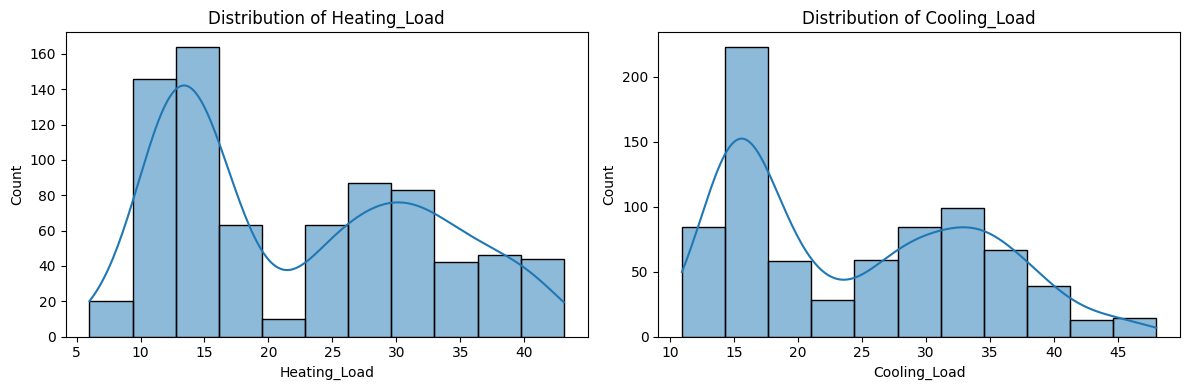

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axs, ["Heating_Load", "Cooling_Load"]):
    sns.histplot(df[target], kde=True, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

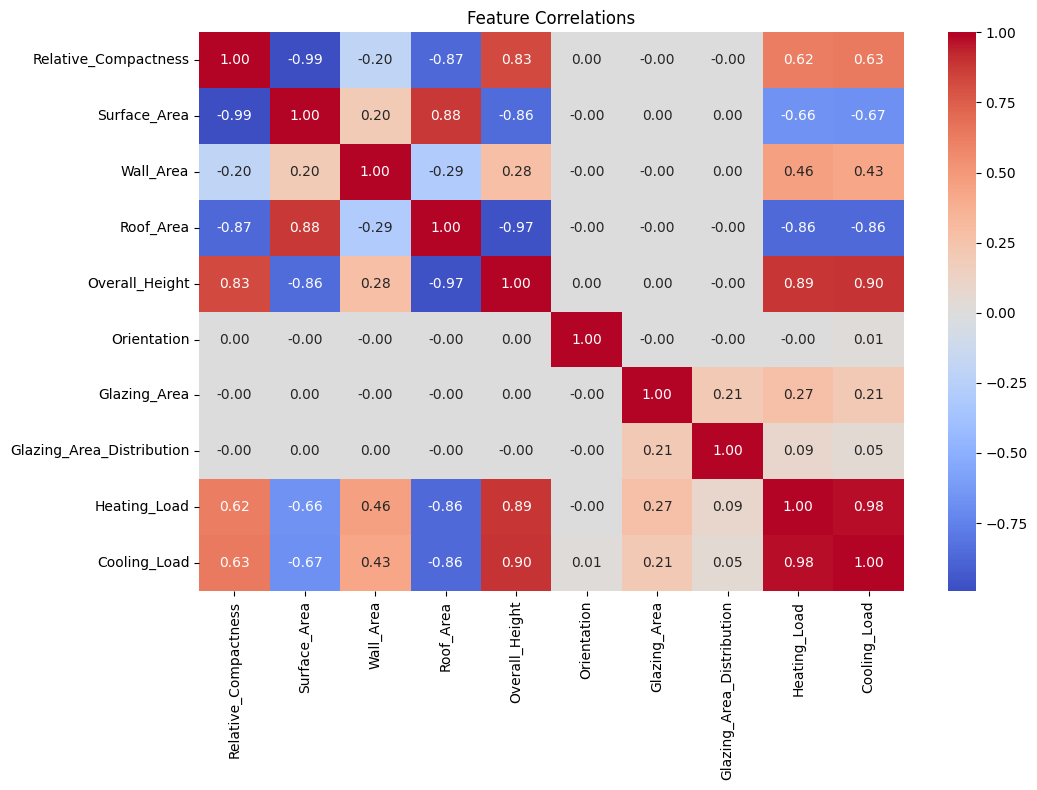

In [ ]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlations")
plt.tight_layout()
plt.show()

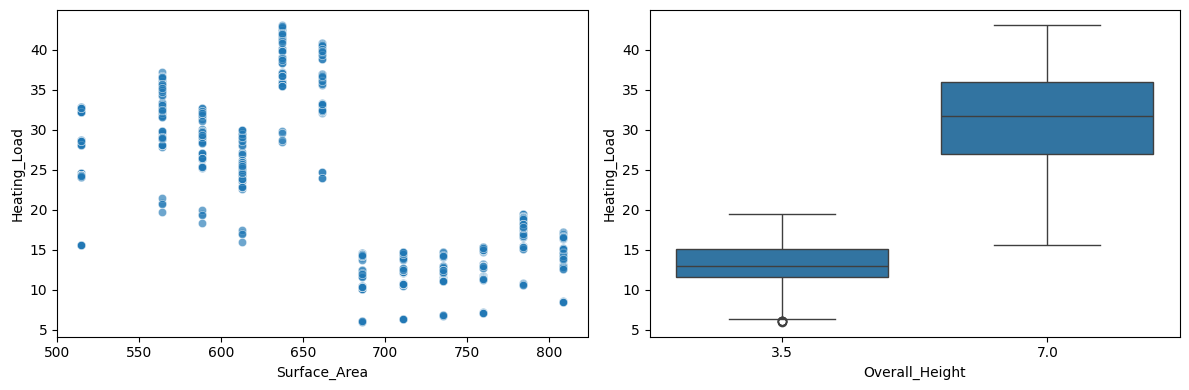

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="Surface_Area", y="Heating_Load", ax=axes[0], alpha=.65)
sns.boxplot(data=df, x="Overall_Height", y="Heating_Load", ax=axes[1])
plt.tight_layout()
plt.show()

## 4. Initial model experiments
Compare Linear Regression to Random Forest using the **same** held-out 20% test set (random_state=42). Each model predicts both energy-load targets. Do not claim these results generalize to real-world buildings: these data are simulations. Note that highly related building configurations can make a random train/test split optimistic.### Model Selection Rationale

Two regression algorithms were selected for comparison:

- **Linear Regression:** A simple and interpretable baseline model used to examine linear relationships between architectural features and heating/cooling loads.
- **Random Forest Regressor:** An ensemble learning model capable of capturing nonlinear relationships and interactions among building characteristics.

Comparing these models helps us evaluate whether additional model complexity improves prediction accuracy. Performance is measured using MAE, RMSE, and R². Generalization to unseen building geometries is evaluated separately.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

targets = ["Heating_Load", "Cooling_Load"]
X = df.drop(columns=targets)
y = df[targets]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    for j, target in enumerate(targets):
        results.append({
            "Model": name, "Target": target,
            "MAE": mean_absolute_error(y_test.iloc[:, j], pred[:, j]),
            "RMSE": np.sqrt(mean_squared_error(y_test.iloc[:, j], pred[:, j])),
            "R2": r2_score(y_test.iloc[:, j], pred[:, j]),
        })
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Target,MAE,RMSE,R2
0,Linear Regression,Heating_Load,2.1820,3.0254,0.9122
1,Linear Regression,Cooling_Load,2.1953,3.1454,0.8932
2,Random Forest,Heating_Load,0.3477,0.4975,0.9976
3,Random Forest,Cooling_Load,1.1664,1.9062,0.9608


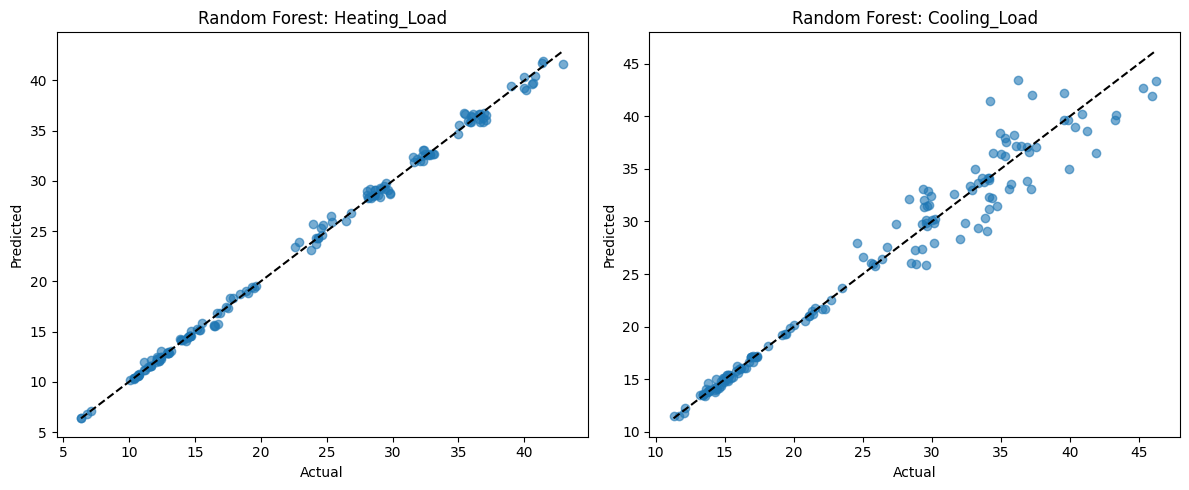

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rf_pred = predictions["Random Forest"]
for idx, target in enumerate(targets):
    actual = y_test.iloc[:, idx].to_numpy()
    pred = rf_pred[:, idx]
    axes[idx].scatter(actual, pred, alpha=.6)
    bounds = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    axes[idx].plot(bounds, bounds, "--", color="black")
    axes[idx].set(xlabel="Actual", ylabel="Predicted", title=f"Random Forest: {target}")
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone
from sklearn.metrics import make_scorer, mean_squared_error

# Assignment 2 — 5-Fold Cross-Validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for model_name, model in models.items():
    for target in targets:
        target_values = y_train[target]

        scores = cross_validate(
            clone(model),
            X_train,
            target_values,
            cv=cv,
            scoring={
                "MAE": "neg_mean_absolute_error",
                "R2": "r2"
            },
            n_jobs=-1
        )

        cv_results.append({
            "Model": model_name,
            "Target": target,
            "CV_MAE_Mean": -scores["test_MAE"].mean(),
            "CV_MAE_Std": scores["test_MAE"].std(),
            "CV_R2_Mean": scores["test_R2"].mean(),
            "CV_R2_Std": scores["test_R2"].std()
        })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df.round(4))


,Model,Target,CV_MAE_Mean,CV_MAE_Std,CV_R2_Mean,CV_R2_Std
0,Linear Regression,Heating_Load,2.0618,0.0950,0.9146,0.0109
1,Linear Regression,Cooling_Load,2.2773,0.1702,0.8829,0.0119
2,Random Forest,Heating_Load,0.3444,0.0276,0.9973,0.0003
3,Random Forest,Cooling_Load,1.0346,0.1155,0.9666,0.0047


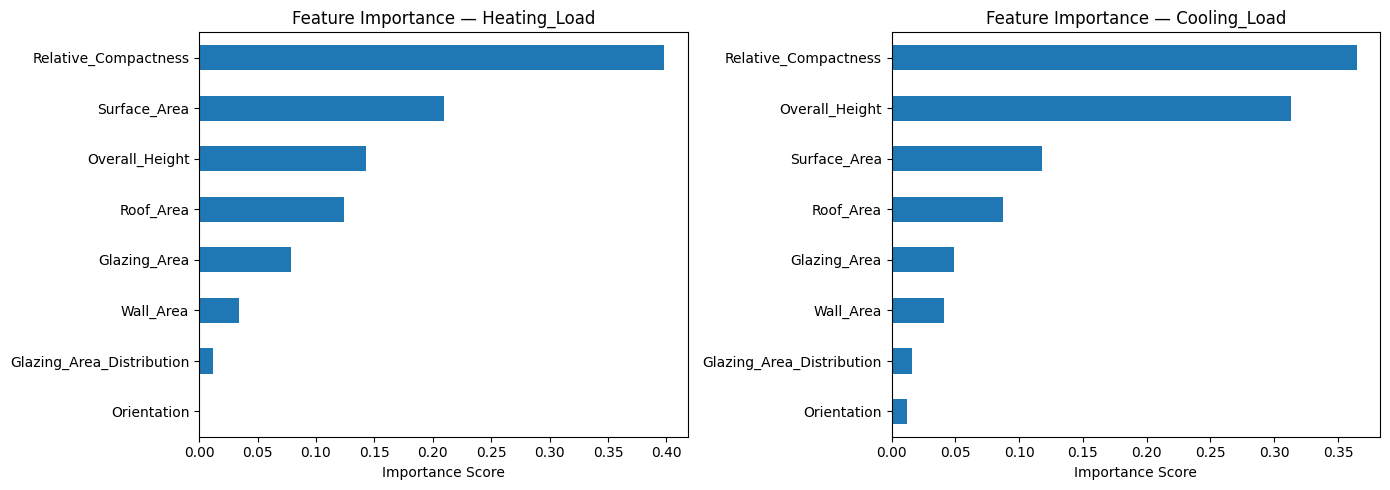

In [ ]:

# Assignment 2 — Feature Importance Analysis

from sklearn.ensemble import RandomForestRegressor

feature_names = X_train.columns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, target in enumerate(targets):
    rf = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )

    rf.fit(X_train, y_train[target])

    importance = pd.Series(
        rf.feature_importances_,
        index=feature_names
    ).sort_values(ascending=True)

    importance.plot(
        kind="barh",
        ax=axes[i]
    )

    axes[i].set_title(f"Feature Importance — {target}")
    axes[i].set_xlabel("Importance Score")

plt.tight_layout()
plt.show()


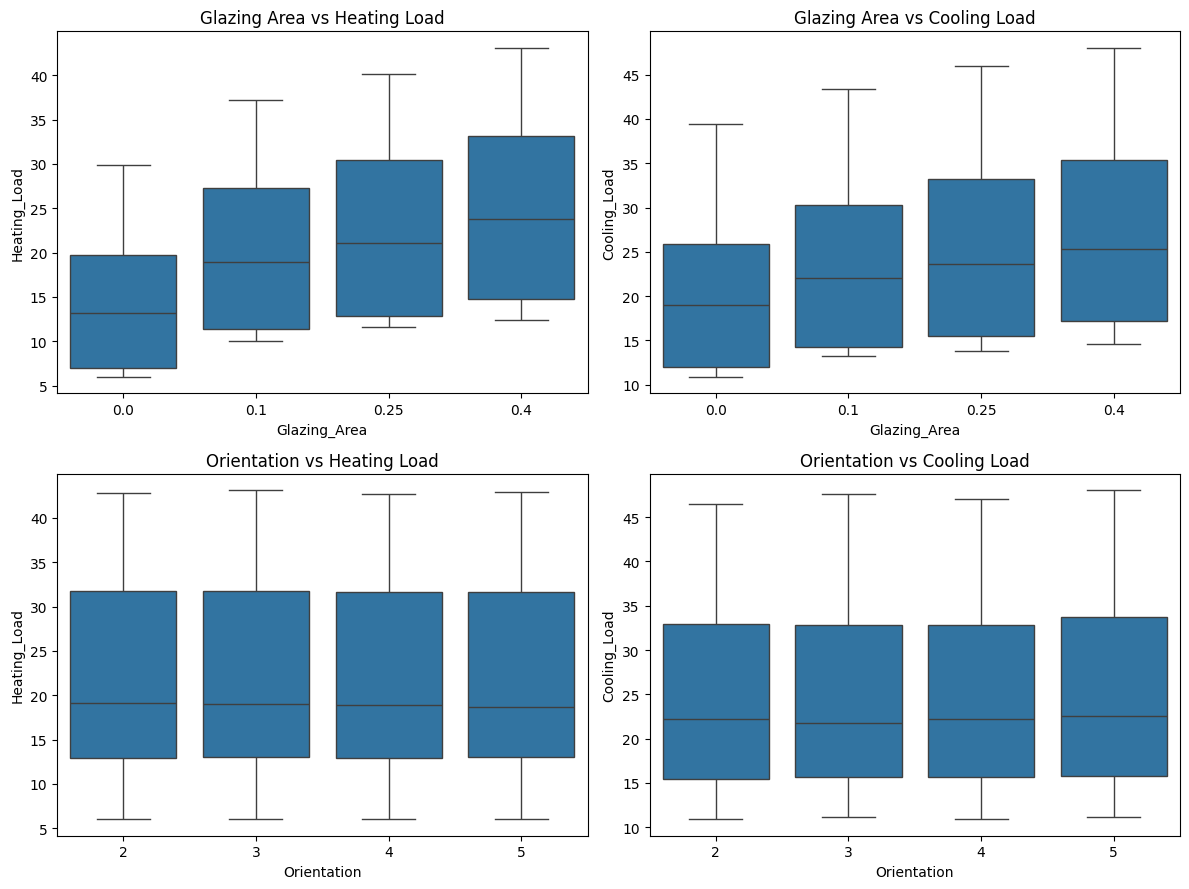

In [ ]:

# Assignment 2 — Glazing Area & Orientation Analysis

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(
    data=df,
    x="Glazing_Area",
    y="Heating_Load",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Glazing Area vs Heating Load")

sns.boxplot(
    data=df,
    x="Glazing_Area",
    y="Cooling_Load",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Glazing Area vs Cooling Load")

sns.boxplot(
    data=df,
    x="Orientation",
    y="Heating_Load",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Orientation vs Heating Load")

sns.boxplot(
    data=df,
    x="Orientation",
    y="Cooling_Load",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Orientation vs Cooling Load")

plt.tight_layout()
plt.show()


In [ ]:

# Assignment 2 — Building Geometry Analysis

geometry_columns = [
    "Relative_Compactness",
    "Surface_Area",
    "Wall_Area",
    "Roof_Area",
    "Overall_Height"
]

# Count unique building geometries
unique_geometries = df[geometry_columns].drop_duplicates()

print("Total dataset rows:", len(df))
print("Unique building geometries:", len(unique_geometries))

# Number of configurations per geometry
geometry_counts = (
    df.groupby(geometry_columns)
      .size()
      .reset_index(name="Configuration_Count")
      .sort_values("Configuration_Count", ascending=False)
)

print("\nConfigurations per geometry:")
display(geometry_counts)

# Check how many glazing and orientation combinations exist
print("\nUnique glazing ratios:", sorted(df["Glazing_Area"].unique()))
print("Unique orientation categories:", sorted(df["Orientation"].unique()))


Total dataset rows: 768
Unique building geometries: 12

Configurations per geometry:


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Configuration_Count
0,0.62,808.5,367.5,220.50,3.5,64
1,0.64,784.0,343.0,220.50,3.5,64
2,0.66,759.5,318.5,220.50,3.5,64
3,0.69,735.0,294.0,220.50,3.5,64
4,0.71,710.5,269.5,220.50,3.5,64
5,0.74,686.0,245.0,220.50,3.5,64
6,0.76,661.5,416.5,122.50,7.0,64
7,0.79,637.0,343.0,147.00,7.0,64
8,0.82,612.5,318.5,147.00,7.0,64
9,0.86,588.0,294.0,147.00,7.0,64



Unique glazing ratios: [np.float64(0.0), np.float64(0.1), np.float64(0.25), np.float64(0.4)]
Unique orientation categories: [np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [ ]:

# Assignment 2 — Geometry-Aware Cross-Validation

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone

geometry_columns = [
    "Relative_Compactness",
    "Surface_Area",
    "Wall_Area",
    "Roof_Area",
    "Overall_Height"
]

# Each unique building geometry receives a group ID.
geometry_groups = pd.factorize(
    pd.MultiIndex.from_frame(df[geometry_columns])
)[0]

print("Unique building geometries:", len(np.unique(geometry_groups)))

# Keep each geometry completely separate during validation.
group_cv = GroupKFold(n_splits=4)

group_results = []

X_all = df.drop(columns=["Heating_Load", "Cooling_Load"])
y_all = df[["Heating_Load", "Cooling_Load"]]

for model_name, model in models.items():
    for target in targets:
        scores = cross_validate(
            clone(model),
            X_all,
            y_all[target],
            groups=geometry_groups,
            cv=group_cv,
            scoring={
                "MAE": "neg_mean_absolute_error",
                "R2": "r2"
            },
            n_jobs=-1
        )

        group_results.append({
            "Model": model_name,
            "Target": target,
            "Group_MAE_Mean": -scores["test_MAE"].mean(),
            "Group_MAE_Std": scores["test_MAE"].std(),
            "Group_R2_Mean": scores["test_R2"].mean(),
            "Group_R2_Std": scores["test_R2"].std()
        })

group_results_df = pd.DataFrame(group_results)
display(group_results_df.round(4))


Unique building geometries: 12


,Model,Target,Group_MAE_Mean,Group_MAE_Std,Group_R2_Mean,Group_R2_Std
0,Linear Regression,Heating_Load,4.1055,1.5445,0.6232,0.1862
1,Linear Regression,Cooling_Load,4.5395,1.2565,0.5246,0.1786
2,Random Forest,Heating_Load,4.2673,1.3707,0.4703,0.2989
3,Random Forest,Cooling_Load,5.0804,0.5364,0.4055,0.1541


In [21]:

# Assignment 2 — Leave-One-Geometry-Out Validation

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score

logo = LeaveOneGroupOut()
logo_results = []

for model_name, model in models.items():
    for target in targets:
        for train_idx, test_idx in logo.split(
            X_all, y_all[target], groups=geometry_groups
        ):
            model_copy = clone(model)

            model_copy.fit(
                X_all.iloc[train_idx],
                y_all[target].iloc[train_idx]
            )

            logo_predictions = model_copy.predict(
                X_all.iloc[test_idx]
            )

            group_id = geometry_groups[test_idx][0]

            logo_results.append({
                "Model": model_name,
                "Target": target,
                "Geometry": int(group_id),
                "MAE": mean_absolute_error(
                    y_all[target].iloc[test_idx],
                    logo_predictions
                ),
                "R2": r2_score(
                    y_all[target].iloc[test_idx],
                    logo_predictions
                )
            })

logo_df = pd.DataFrame(logo_results)

summary = (
    logo_df.groupby(["Model", "Target"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_R2=("R2", "mean"),
        Std_R2=("R2", "std")
    )
    .reset_index()
)

display(summary.round(4))


,Model,Target,Mean_MAE,Std_MAE,Mean_R2,Std_R2
0,Linear Regression,Cooling_Load,3.9327,3.3477,-3.7171,5.6715
1,Linear Regression,Heating_Load,3.5103,3.1839,-1.1999,2.6767
2,Random Forest,Cooling_Load,4.9690,3.6881,-6.3632,9.7484
3,Random Forest,Heating_Load,4.3506,4.4935,-3.9048,8.7196


,Model,Target,MAE,Validation
0,Linear Regression,Heating_Load,2.0618,Random 5-Fold
1,Linear Regression,Cooling_Load,2.2773,Random 5-Fold
2,Random Forest,Heating_Load,0.3444,Random 5-Fold
3,Random Forest,Cooling_Load,1.0346,Random 5-Fold
4,Linear Regression,Heating_Load,2.8749,Geometry-Aware 4-Fold
5,Linear Regression,Cooling_Load,3.5509,Geometry-Aware 4-Fold
6,Random Forest,Heating_Load,4.1475,Geometry-Aware 4-Fold
7,Random Forest,Cooling_Load,3.8476,Geometry-Aware 4-Fold


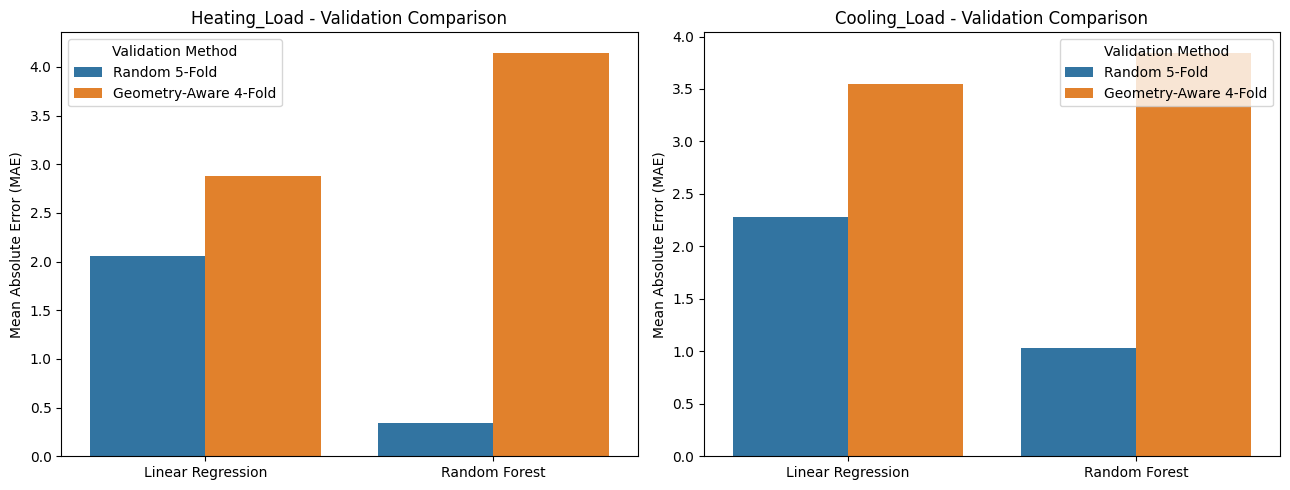

In [19]:

# Assignment 2 — Validation Strategy Comparison

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone

# Use the same training data for both validation strategies.
train_geometry_groups = geometry_groups[X_train.index]

group_cv_train = GroupKFold(n_splits=4)
group_train_results = []

for model_name, model in models.items():
    for target in targets:
        scores = cross_validate(
            clone(model),
            X_train,
            y_train[target],
            groups=train_geometry_groups,
            cv=group_cv_train,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        group_train_results.append({
            "Model": model_name,
            "Target": target,
            "MAE": -scores["test_score"].mean(),
            "Validation": "Geometry-Aware 4-Fold"
        })

# Previously calculated random CV on the training set.
random_comparison = cv_results_df[
    ["Model", "Target", "CV_MAE_Mean"]
].copy()

random_comparison = random_comparison.rename(
    columns={"CV_MAE_Mean": "MAE"}
)
random_comparison["Validation"] = "Random 5-Fold"

geometry_comparison = pd.DataFrame(group_train_results)

comparison_df = pd.concat(
    [random_comparison, geometry_comparison],
    ignore_index=True
)

display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, target in enumerate(targets):
    subset = comparison_df[
        comparison_df["Target"] == target
    ]

    sns.barplot(
        data=subset,
        x="Model",
        y="MAE",
        hue="Validation",
        ax=axes[i]
    )

    axes[i].set_title(f"{target} - Validation Comparison")
    axes[i].set_ylabel("Mean Absolute Error (MAE)")
    axes[i].set_xlabel("")
    axes[i].legend(title="Validation Method")

plt.tight_layout()
plt.show()


Saving TUR_IB_Istanbul-Ataturk.AP.170600_TMYx.2009-2023.epw to TUR_IB_Istanbul-Ataturk.AP.170600_TMYx.2009-2023.epw
Hourly weather records: 8760
Temperature minimum: 0.1
Temperature maximum: 34.0


,Mean_Temperature,Mean_Humidity,Total_Solar_Radiation
Month,,,
1,7.48,75.91,55999
2,8.37,76.15,67492
3,9.09,77.32,121469
4,12.79,72.24,159461
5,18.24,69.48,199091
6,23.00,71.76,201079
7,26.00,62.23,214198
8,26.41,66.75,190450
9,22.30,66.62,144696


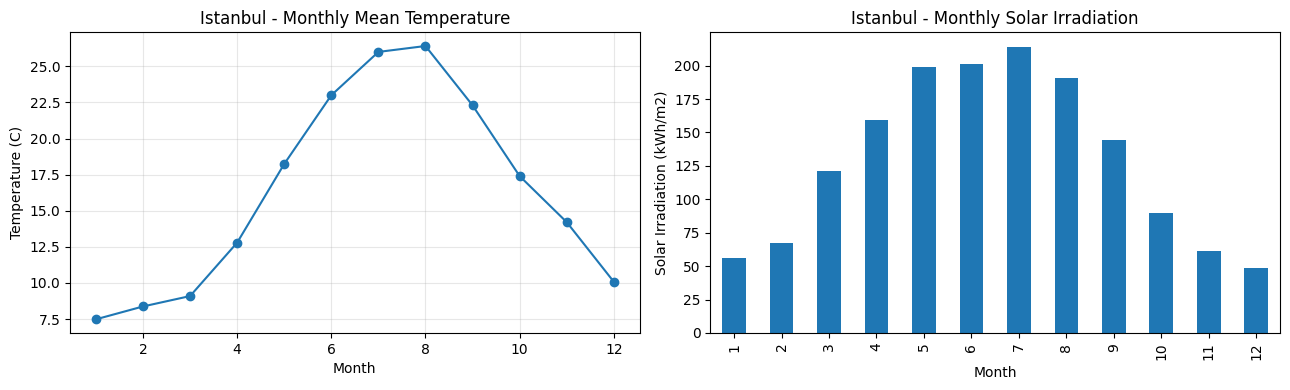

In [ ]:

# Assignment 2 — Istanbul Climate Data Analysis
# Source: Climate.OneBuilding TMYx 2009-2023

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded_weather = files.upload()
epw_filename = next(
    name for name in uploaded_weather
    if name.lower().endswith(".epw")
)

# EPW files contain 8 header lines followed by hourly data
weather = pd.read_csv(
    epw_filename,
    skiprows=8,
    header=None
)

# EPW column positions
weather_data = pd.DataFrame({
    "Month": weather.iloc[:, 1],
    "Dry_Bulb_Temperature": weather.iloc[:, 6],
    "Relative_Humidity": weather.iloc[:, 8],
    "Global_Horizontal_Radiation": weather.iloc[:, 13]
})

monthly_climate = weather_data.groupby("Month").agg(
    Mean_Temperature=("Dry_Bulb_Temperature", "mean"),
    Mean_Humidity=("Relative_Humidity", "mean"),
    Total_Solar_Radiation=("Global_Horizontal_Radiation", "sum")
).round(2)

print("Hourly weather records:", len(weather_data))
print("Temperature minimum:",
      weather_data["Dry_Bulb_Temperature"].min())
print("Temperature maximum:",
      weather_data["Dry_Bulb_Temperature"].max())

display(monthly_climate)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

monthly_climate["Mean_Temperature"].plot(
    ax=axes[0], marker="o"
)
axes[0].set_title("Istanbul - Monthly Mean Temperature")
axes[0].set_ylabel("Temperature (C)")
axes[0].set_xlabel("Month")
axes[0].grid(alpha=0.3)

# Sum of hourly Wh/m2 values gives monthly Wh/m2
(monthly_climate["Total_Solar_Radiation"] / 1000).plot(
    ax=axes[1], kind="bar"
)
axes[1].set_title("Istanbul - Monthly Solar Irradiation")
axes[1].set_ylabel("Solar Irradiation (kWh/m2)")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()



## Assignment 2 — Results and Discussion

### Model Performance

Random Forest achieved strong performance under random
5-fold cross-validation:

- Heating Load: R² = 0.9973, MAE = 0.3444
- Cooling Load: R² = 0.9666, MAE = 1.0346

However, further analysis revealed that the dataset
contains only 12 unique building geometries, each
represented by 64 configurations.

### Geometry-Aware Validation

When building geometries were separated between
training and validation sets, model performance
decreased substantially.

Random Forest results under geometry-aware 4-fold
cross-validation:

- Heating Load: R² = 0.4703, MAE = 4.2673
- Cooling Load: R² = 0.4055, MAE = 5.0804

Linear Regression performed better than Random Forest
under this evaluation strategy.

These findings demonstrate that strong performance
under random validation does not necessarily imply
reliable predictions for unseen building geometries.

### Validation Strategy Comparison

To ensure a more consistent comparison, random 5-fold cross-validation and geometry-aware 4-fold cross-validation were additionally evaluated on the same 80% training subset. Although the number of folds differed, both methods used the same pool of training observations. The results confirmed that prediction errors increased when previously unseen building geometries were used for validation, especially for Random Forest. The full-dataset geometry-aware results reported above are retained as a separate experiment.

### Feature Analysis

Feature importance analysis identified relative
compactness, overall height, and surface area among
the most influential features.

Exploratory analysis also examined glazing ratios
and orientation categories.

Higher glazing ratios were generally associated
with higher heating and cooling loads in this dataset.
Orientation categories showed relatively similar
distributions.

These findings are descriptive and do not establish
causal effects.

### Istanbul Climate Analysis

An Istanbul Ataturk Airport TMYx 2009–2023 EPW
weather file was analyzed.

The dataset contains 8,760 hourly weather records.

- January mean temperature: 7.48 °C
- August mean temperature: 26.41 °C
- Highest monthly solar irradiation:
  July, approximately 214.2 kWh/m²

This climate analysis is separate from the trained
energy load prediction models.

### Limitations and Future Work

The original dataset consists of simulated building
configurations and includes only 12 distinct geometries.

The models have not been validated using measured
energy data from real buildings.

Future work will investigate the use of EnergyPlus
to generate additional building simulations using
Istanbul climate conditions.

The planned research will focus on how glazing ratio
and building orientation influence heating and
cooling loads under controlled building configurations.

No Istanbul-specific building energy load model has
been developed at this stage.

### Sustainability and SDG Alignment

This project aligns with UN Sustainable Development Goal 7 (Affordable and Clean Energy) and Goal 13 (Climate Action) by exploring how architectural design characteristics relate to building heating and cooling demands.

The findings highlight the potential role of machine learning in supporting early-stage energy-conscious building design decisions. However, the current models predict simulated heating and cooling loads rather than measured energy consumption, electricity costs, or carbon emissions.

Future Istanbul-specific simulations and broader validation could help assess the practical relevance of the approach to local building energy efficiency. No energy savings or emission reductions have been demonstrated at this stage.


## References

**Citation:** Tsanas, A. and Xifara, A. (2012), Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools, *Energy and Buildings*, 49, 560–567. Dataset: UCI Energy Efficiency (https://archive.ics.uci.edu/dataset/242/energy+efficiency).